<a href="https://colab.research.google.com/github/ahlammk1987-cpu/vit-d3/blob/main/vit_d3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Étape 1 : Connexion à Google Drive
Exécutez cette cellule pour autoriser l'accès à vos fichiers Google Drive.

In [24]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Étape 2 : Chargement des données et Visualisation
Nous allons charger le fichier Excel et afficher un aperçu ainsi qu'un graphique de base.

Données chargées avec succès !


,age,sex,sang_ha,first_second,which_exam,exam_id,exam_date,work_division,office_code,office_name,...,koss_s3,koss_s4,koss_s5,koss_s6,koss_s7,koss_s8,sleeplessness,day_alert,dig_s,breast_s
0,37,남,상,1,특수검진,2314085,20190401,금형개발혁신그룹(GTC),H2777,삼성전자(주)구미1사업장,...,100,88.9,76.2,72.2,66.7,55.6,NaN,NaN,NaN,NaN
1,39,남,상,1,특수검진,7307126,20190415,INFRA기술1(구미),H2777,삼성전자(주)구미1사업장,...,33.3,38.9,33.3,33.3,41.7,22.2,9 ☞ 정상,NaN,정상,NaN
2,32,남,상,1,특수검진,14305117,20190419,H/W검증그룹(네트워크),H2777,삼성전자(주)구미1사업장,...,16.7,38.9,38.1,38.9,25,33.3,NaN,NaN,NaN,NaN
3,27,남,상,1,특수검진,14305035,20190401,선행메카파트(무선),H2777,삼성전자(주)구미1사업장,...,33.3,44.4,42.9,44.4,33.3,44.4,1 ☞ 정상,NaN,정상,NaN
4,27,남,상,1,특수검진,14305046,20190402,INFRA기술1(구미),H2777,삼성전자(주)구미1사업장,...,33.3,38.9,42.9,33.3,33.3,33.3,2 ☞ 정상,NaN,정상,NaN


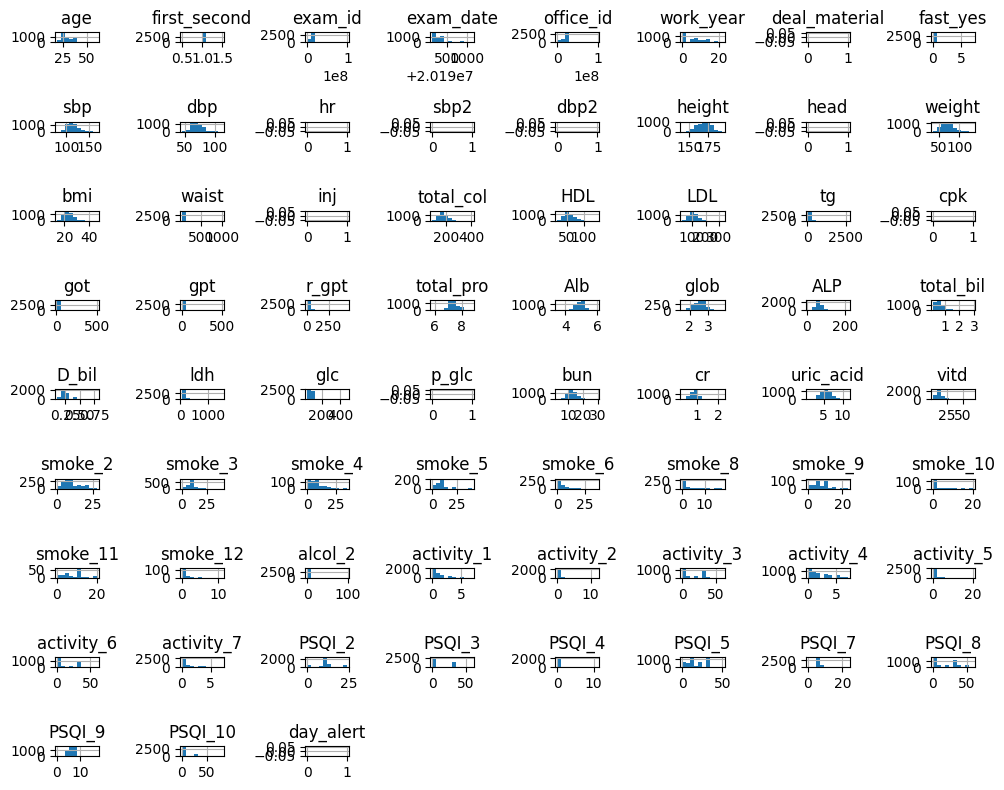

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Chemin d'accès au fichier
file_path = '/content/drive/MyDrive/Colab Notebooks/rawdata(for CI).xlsx'

# Chargement des données
try:
    df = pd.read_excel(file_path)
    print("Données chargées avec succès !")
    display(df.head())

    # Visualisation de base (par exemple, distribution des variables numériques)
    # Vous pouvez adapter cette section selon la structure de vos colonnes
    df.hist(figsize=(10, 8))
    plt.tight_layout()
    plt.show()
except Exception as e:
    print("Une erreur est survenue lors du chargement : ", e)

### Étape 3 : Identification des relations entre caractéristiques (X) et cibles (Y)
Nous allons utiliser une approche d'apprentissage automatique (Random Forest) pour évaluer l'importance des variables prédictives (X) par rapport à une variable cible (Y), ce qui est couramment utilisé en bio-informatique et pharmacologie clinique pour identifier des biomarqueurs ou des facteurs de risque.

/tmp/ipykernel_503/2215861105.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances[indices[:top_k]], y=X.columns[indices[:top_k]], palette='viridis')


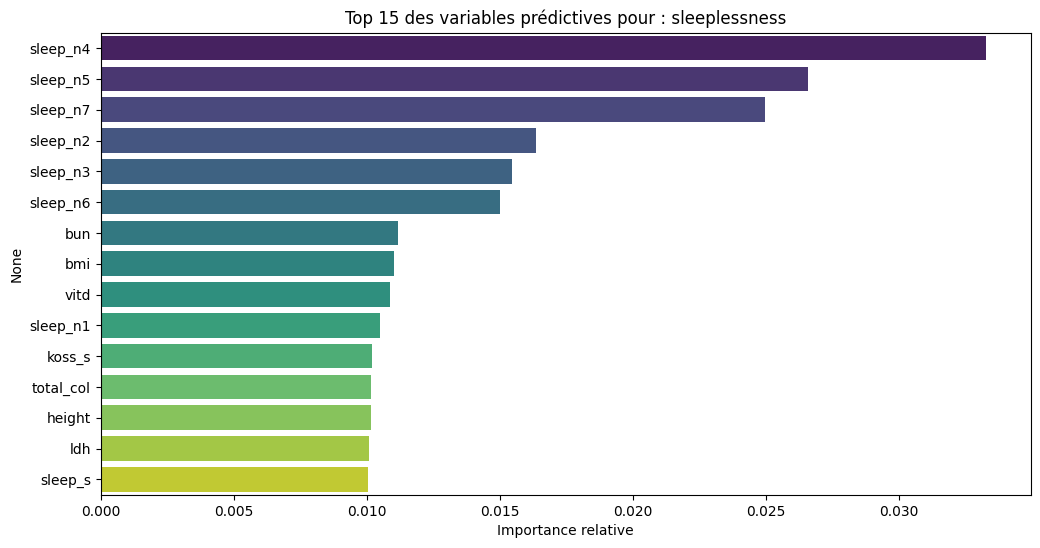

In [26]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns

# Définissons d'abord notre cible (Y) et nos variables prédictives (X)
# Exemple : Nous prenons 'sleeplessness' ou 'age' comme cible (Y) selon le type de données.
# Vous pouvez modifier le nom de la variable cible ci-dessous :
target_column = 'sleeplessness'

if target_column in df.columns:
    # Nettoyage rapide pour l'exemple
    data_subset = df.copy()

    # Supprimer les lignes où la cible est manquante
    data_subset = data_subset.dropna(subset=[target_column])

    # Encodage des variables qualitatives (catégorielles)
    le = LabelEncoder()
    for col in data_subset.select_dtypes(include=['object']).columns:
        data_subset[col] = le.fit_transform(data_subset[col].astype(str))

    # Séparation X et Y
    Y = data_subset[target_column]
    X = data_subset.drop(columns=[target_column])

    # Remplissage des valeurs manquantes dans X pour l'algorithme
    X = X.fillna(X.median())

    # Entraînement d'un modèle de Forêt Aléatoire pour évaluer l'importance
    # (Adapté pour les données biologiques complexes et non-linéaires)
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X, Y)

    # Extraction des importances
    importances = model.feature_importances_
    indices = np.argsort(importances)[::-1]

    # Affichage des 15 caractéristiques les plus prédictives
    top_k = min(15, X.shape[1])
    plt.figure(figsize=(12, 6))
    plt.title(f"Top {top_k} des variables prédictives pour : {target_column}")
    sns.barplot(x=importances[indices[:top_k]], y=X.columns[indices[:top_k]], palette='viridis')
    plt.xlabel("Importance relative")
    plt.show()
else:
    print(f"La colonne cible '{target_column}' n'a pas été trouvée. Veuillez choisir une colonne existante de votre DataFrame.")

### Étape 4 : Séparation des données (80% Entraînement / 20% Test)
Nous utilisons la fonction `train_test_split` de la bibliothèque `scikit-learn` pour segmenter notre jeu de données de manière aléatoire et reproductible grâce au paramètre `random_state`.

In [27]:
from sklearn.model_selection import train_test_split

# Séparation des données en 80% train et 20% test
# Retrait de l'argument 'stratify' pour éviter l'erreur sur les classes à effectif unique
X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.20,
    random_state=42
)

# Affichage des dimensions des ensembles générés
print(f"Taille globale de X : {X.shape}")
print(f"Taille de X_train (Entraînement 80%) : {X_train.shape}")
print(f"Taille de X_test (Vérification 20%) : {X_test.shape}")

Taille globale de X : (2146, 279)
Taille de X_train (Entraînement 80%) : (1716, 279)
Taille de X_test (Vérification 20%) : (430, 279)
